<a href="https://colab.research.google.com/github/SamuelChristianAd/hasil-laporan-kelompok.AVD/blob/main/Data_Kelompok.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ==================
# ANGGOTA KELOMPOK
# ==================
1. Amadeo Abqary Dhiyaulhaq
2. M. Akbar Al Farizi
3. SAmual Cristian Adi
4. Zaki Khoirudin Adi

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat Dataset (sesuaikan path jika berbeda)
df_diamond = pd.read_csv('/content/diamonds.csv')

# Menghapus kolom indeks bawaan seperti 'Unnamed: 0' jika ada
if 'Unnamed: 0' in df_diamond.columns:
    df_diamond = df_diamond.drop(columns=['Unnamed: 0'])

print("--- 1. 5 Baris Pertama Data Diamonds ---")
print(df_diamond.head())

print("\n--- 2. Cek Data Kosong & Duplikat ---")
print("Jumlah Data Kosong per Kolom:\n", df_diamond.isnull().sum())
print("\nJumlah Data Duplikat:", df_diamond.duplicated().sum())

# Menghapus data duplikat jika ditemukan agar analisis bersih
df_diamond = df_diamond.drop_duplicates()

print("\n--- 3. Informasi Tipe Data & Ringkasan Statistik ---")
print(df_diamond.info())
print("\nRingkasan Statistik Numerik:")
print(df_diamond.describe())

--- 1. 5 Baris Pertama Data Diamonds ---
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75

--- 2. Cek Data Kosong & Duplikat ---
Jumlah Data Kosong per Kolom:
 carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Jumlah Data Duplikat: 146

--- 3. Informasi Tipe Data & Ringkasan Statistik ---
<class 'pandas.core.frame.DataFrame'>
Index: 53794 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53794 non-null  float64
 1   cut      53794 n

In [ ]:
# ==========================================
# ANALISIS STATISTIK DESKRIPTIF KUNCI
# ==========================================
print("--- 5 STATISTIK DESKRIPTIF KUNCI ---")
print(f"1. Total Data Berlian Bersih : {len(df_diamond):,} baris")
print(f"2. Rata-rata Harga (Mean)    : ${df_diamond['price'].mean():,.2f}")
print(f"3. Median Harga (Nilai Tengah): ${df_diamond['price'].median():,.2f}")
print(f"4. Rata-rata Berat (Carat)   : {df_diamond['carat'].mean():.2f} carat")
print(f"5. Kategori Cut Terbanyak    : {df_diamond['cut'].mode()[0]} ({df_diamond['cut'].value_counts().iloc[0]:,} unit)")

# ==========================================
# DETEKSI OUTLIER HARGA (ATURAN IQR)
# ==========================================
Q1 = df_diamond['price'].quantile(0.25)
Q3 = df_diamond['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_price = df_diamond[(df_diamond['price'] < lower_bound) | (df_diamond['price'] > upper_bound)]

print("\n--- DETEKSI OUTLIER HARGA (IQR) ---")
print(f"Q1 (25%)          : ${Q1:,.2f}")
print(f"Q3 (75%)          : ${Q3:,.2f}")
print(f"IQR               : ${IQR:,.2f}")
print(f"Batas Atas Harga  : ${upper_bound:,.2f}")
print(f"Jumlah Outlier    : {len(outliers_price):,} berlian (harga di atas ${upper_bound:,.2f})")

--- 5 STATISTIK DESKRIPTIF KUNCI ---
1. Total Data Berlian Bersih : 53,794 baris
2. Rata-rata Harga (Mean)    : $3,933.07
3. Median Harga (Nilai Tengah): $2,401.00
4. Rata-rata Berat (Carat)   : 0.80 carat
5. Kategori Cut Terbanyak    : Ideal (21,488 unit)

--- DETEKSI OUTLIER HARGA (IQR) ---
Q1 (25%)          : $951.00
Q3 (75%)          : $5,326.75
IQR               : $4,375.75
Batas Atas Harga  : $11,890.38
Jumlah Outlier    : 3,523 berlian (harga di atas $11,890.38)


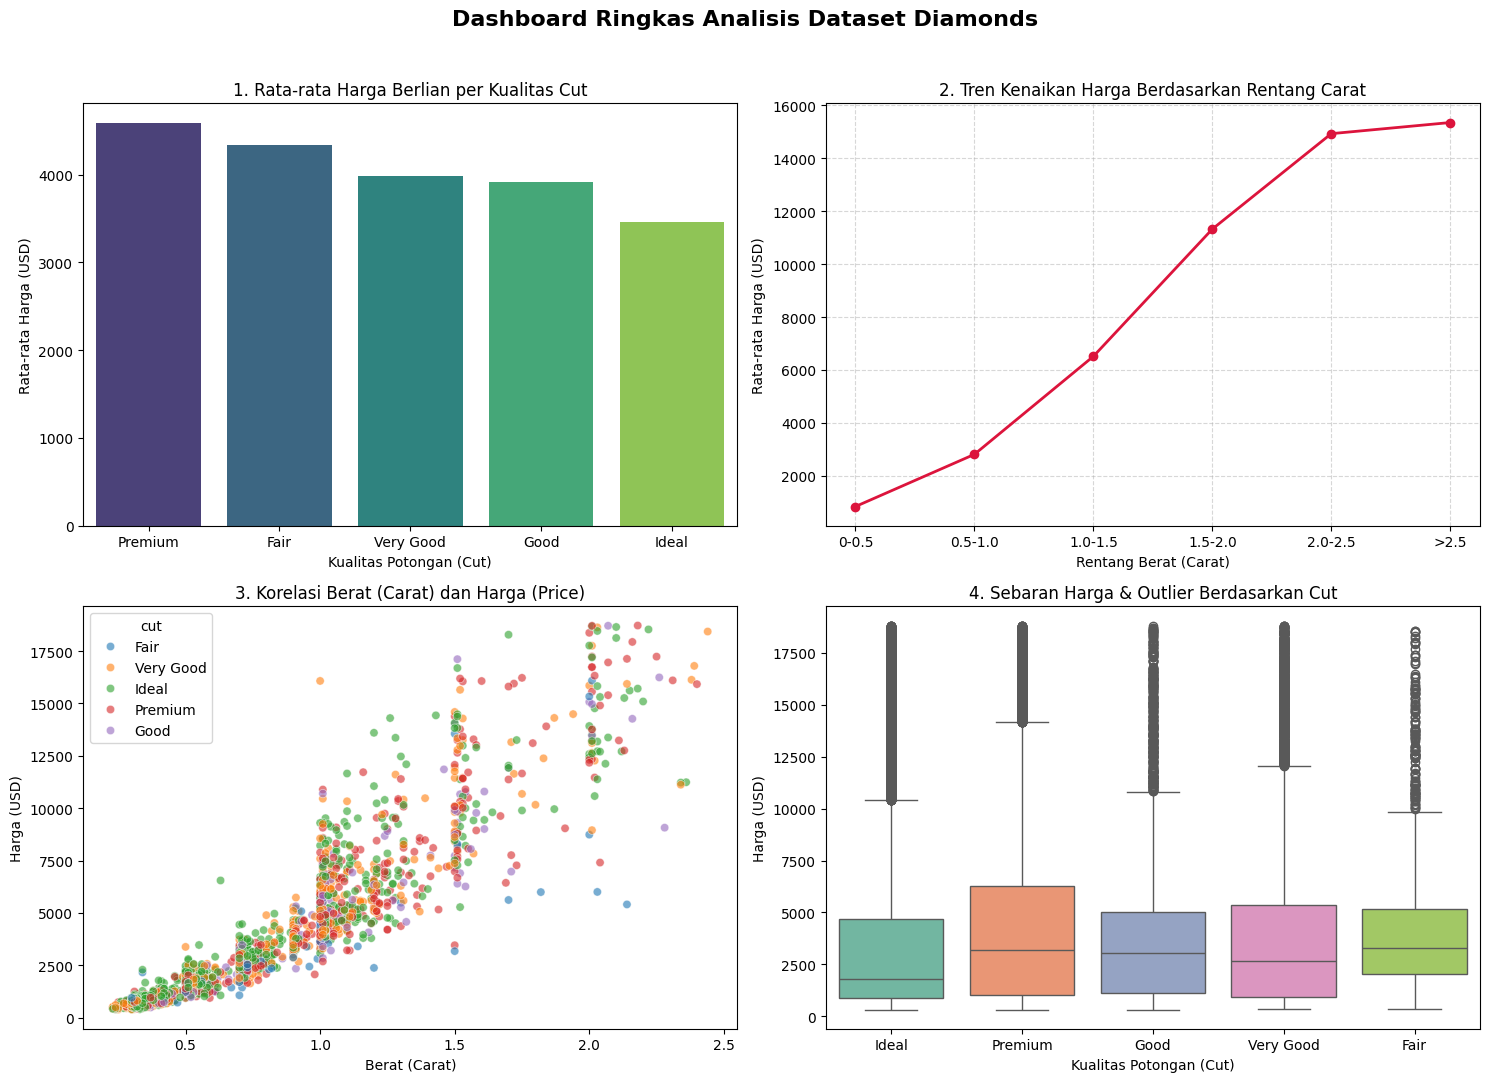

In [ ]:
# Menyiapkan data agregasi untuk Bar Plot dan Line Plot
avg_price_cut = df_diamond.groupby('cut')['price'].mean().sort_values(ascending=False).reset_index()

# Membuat kategori kelompok carat untuk tren Line Plot
df_diamond['carat_bin'] = pd.cut(df_diamond['carat'], bins=[0, 0.5, 1.0, 1.5, 2.0, 2.5, 6.0], labels=['0-0.5', '0.5-1.0', '1.0-1.5', '1.5-2.0', '2.0-2.5', '>2.5'])
tren_carat = df_diamond.groupby('carat_bin', observed=False)['price'].mean().reset_index()

# Membuat Canvas Subplot 2x2
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Dashboard Ringkas Analisis Dataset Diamonds', fontsize=16, fontweight='bold')

# 1. Bar Plot: Rata-rata Harga berdasarkan Kualitas Potongan (Cut)
sns.barplot(data=avg_price_cut, x='cut', y='price', hue='cut', palette='viridis', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('1. Rata-rata Harga Berlian per Kualitas Cut')
axes[0, 0].set_xlabel('Kualitas Potongan (Cut)')
axes[0, 0].set_ylabel('Rata-rata Harga (USD)')

# 2. Line Plot: Tren Kenaikan Harga berdasarkan Rentang Berat (Carat)
axes[0, 1].plot(tren_carat['carat_bin'].astype(str), tren_carat['price'], marker='o', color='crimson', linewidth=2)
axes[0, 1].set_title('2. Tren Kenaikan Harga Berdasarkan Rentang Carat')
axes[0, 1].set_xlabel('Rentang Berat (Carat)')
axes[0, 1].set_ylabel('Rata-rata Harga (USD)')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# 3. Scatter Plot: Hubungan Berat (Carat) vs Harga (Price)
# Menggunakan sampel 2000 data agar plot tidak terlalu berat dan lebih jelas dibaca
sample_df = df_diamond.sample(n=min(2000, len(df_diamond)), random_state=42)
sns.scatterplot(data=sample_df, x='carat', y='price', hue='cut', alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title('3. Korelasi Berat (Carat) dan Harga (Price)')
axes[1, 0].set_xlabel('Berat (Carat)')
axes[1, 0].set_ylabel('Harga (USD)')

# 4. Boxplot: Sebaran Harga & Deteksi Outlier per Kategori Cut
sns.boxplot(data=df_diamond, x='cut', y='price', hue='cut', palette='Set2', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('4. Sebaran Harga & Outlier Berdasarkan Cut')
axes[1, 1].set_xlabel('Kualitas Potongan (Cut)')
axes[1, 1].set_ylabel('Harga (USD)')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ===================================
# ANALISIS STATISTIK DESKRIPTIF KUNCI
# ===================================

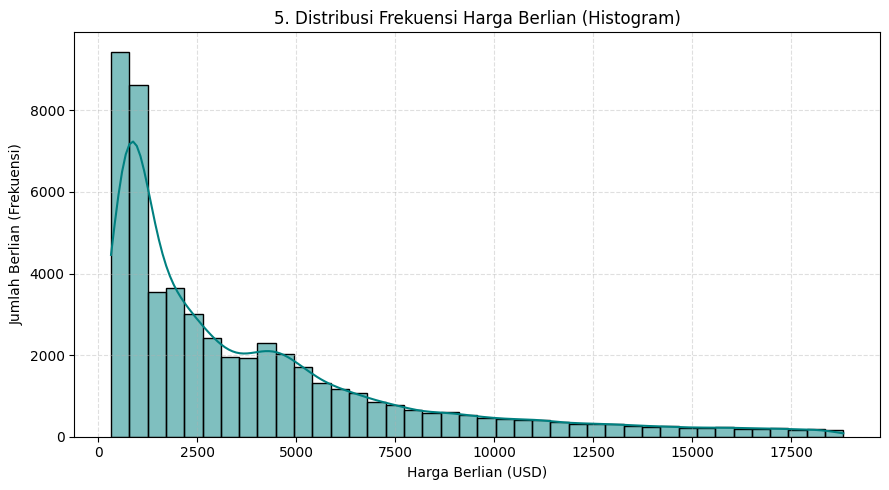

In [ ]:
# 5. Histogram: Distribusi Frekuensi Harga Berlian
plt.figure(figsize=(9, 5))
sns.histplot(df_diamond['price'], bins=40, kde=True, color='teal')
plt.title('5. Distribusi Frekuensi Harga Berlian (Histogram)')
plt.xlabel('Harga Berlian (USD)')
plt.ylabel('Jumlah Berlian (Frekuensi)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


# =====================================
# ANALISIS HARGA BERLIAN DENGAN JUMLAH
# =====================================
Seperti Yang ditampilkan pada grafik kita dapat mengetahui bahwa, semakin lama jumlah berlian semakin sedikit. Tetapi harga meningkan lebih tinggi hingga mencapai harga $17500 USD atau setara dengan Rp 319.000.000 (kurs saat ini)